# CartPole: six readouts × five training seeds

Compare **30 independent training runs**: shared Pauli features, per-action
sums, parity at a=2 and a=4, and majority at a=2 and a=4, with the exact same readout definitions as
the validation notebook. Each run uses four qubits, **four ansatz layers**, Y/Z
rotations, trainable Y encoding, data reuploading, and **CNOT ring entanglement**
`0 → 1 → 2 → 3 → 0` after every layer.

The training budget remains **400 episodes per run**. Seeds 7–11 are paired
across readouts. Every run has fresh circuit/head initialization, optimizer,
replay memory, target network and exploration state. Original CartPole rewards
are retained. Final evaluation is greedy and separate from exploration.

This is a longer experiment. Completed runs are reused only when their full
specification matches. Interrupted, incomplete runs restart from the beginning.
The earlier two-layer single-seed results remain in their original directory.
Presets expose distinct non-identity Pauli-Z expectations directly to a biased
fully connected layer; they do not reconstruct action probabilities. Shared
features omit the redundant identity and use a bias. The per-action control
retains its previous identity terms and bias-free head. Preset size a controls
feature construction independently of the two environment actions. Majority
uses blocks [[0,1,2,3]] for a=2 and [[0,1,2],[3]] for a=4.
The original 20-run projector/no-bias dataset is preserved separately.


In [1]:
from pathlib import Path
import sys, json, platform
from copy import deepcopy
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "qasp").is_dir())
for path in [ROOT, ROOT / "examples"]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
import numpy as np
import pandas as pd
import torch
import pennylane as qml
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown, HTML, Code
from pqdqn_cartpole_experiment import (
    BASE_CONFIG, READOUTS, TRAINING, save_circuit_drawing,
    run_experiments, aggregate_results,
)
from qasp.rl import create_qfunction, DeepQLearning

torch.set_num_threads(1)
BASE_CONFIG, READOUTS = deepcopy(BASE_CONFIG), deepcopy(READOUTS)
print({"python": platform.python_version(), "torch": torch.__version__,
       "pennylane": qml.__version__, "gymnasium": gym.__version__})
print(json.dumps(BASE_CONFIG, indent=2))
print(json.dumps(READOUTS, indent=2))


{'python': '3.13.3', 'torch': '2.14.1', 'pennylane': '0.45.1', 'gymnasium': '1.4.0'}
{
  "ansatz": "AngleAnsatz",
  "ansatz_config": {
    "n_layers": 4,
    "rotations": "YZ",
    "reuploading": true,
    "include_imprimitive": true,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "ring",
    "include_final_imprimitive": true
  },
  "feature_map": "AngleEmbedding",
  "feature_map_config": {
    "features": 4,
    "rotations": "Y",
    "input_scaling": true
  },
  "fc_layer": true,
  "device": "default.qubit",
  "diff_method": "backprop",
  "batch_mode": "broadcast"
}
{
  "shared": {
    "observables": [
      "Z 0",
      "Z 1",
      "Z 2",
      "Z 3"
    ],
    "fc_bias": true
  },
  "per_action": {
    "observables": [
      [
        "I 0",
        "Z 0",
        "Z 2"
      ],
      [
        "I 0",
        "Z 1",
        "Z 3"
      ]
    ],
    "fc_bias": false
  },
  "parity_a2": {
    "observables": "parity-like",
    "preset_actions": 2,
    "fc_bias": true
  },
  "pa

## Experiment settings

The imported definitions are shared with the validation notebook to prevent
circuit or readout drift. Change the dictionaries below and choose a new output
directory for a different experiment. The worker module contains the same
`create_qfunction` → `DeepQLearning.train` loop used in the original notebook.
Four independent worker processes keep the execution manageable.

In [2]:
SEEDS = list(range(7, 12))
EPISODES = 400
MOVING_WINDOW = 20
MAX_WORKERS = 4
EVAL_EPISODES = 20
HELD_OUT_EPISODES = 100
OUTPUT = ROOT / "examples" / "results" / "pqdqn_cartpole_pauli_features_bias_v2_400ep_5seeds"
TRAINING = deepcopy(TRAINING)
assert len(SEEDS) == 5 and len(set(SEEDS)) == 5
assert BASE_CONFIG["ansatz_config"]["n_layers"] == 4
assert BASE_CONFIG["ansatz_config"]["imprimitive"] == "CNOT"
assert BASE_CONFIG["ansatz_config"]["imprimitive_pattern"] == "ring"
print(f"{len(READOUTS)} readouts × {len(SEEDS)} seeds × {EPISODES} episodes")
print(json.dumps(TRAINING, indent=2))

6 readouts × 5 seeds × 400 episodes
{
  "lr": 0.01,
  "gamma": 0.99,
  "batch_size": 64,
  "learning_starts": 256,
  "train_frequency": 4,
  "target_update_interval": 100,
  "epsilon_decay_steps": 8000
}


## Quantikz circuit gallery for all 30 readout/seed configurations

The first seed for each readout is shown directly; the other four appear in
expandable entries. Every entry provides its own vector PDFs and TikZ sources.
Figures use symbolic parameters, so matching architectures have matching
figures despite independent initializations. The entire first layer is expanded;
U₂, U₃, and U₄ each include data reuploading, rotations, and a CNOT ring.
Here **f = tanh(s)** and Θ_l includes the layer's rotations and input scalings.
Measurement meters show local bases; `_readout.json` records the exact Pauli
products and fixed classical coefficients for each readout.

This gallery can be generated before the long training cell. Rendering requires
`pdflatex` with Quantikz and `pdftoppm` (or macOS `sips`).

## Shared

{
  "observables": [
    "Z 0",
    "Z 1",
    "Z 2",
    "Z 3"
  ],
  "fc_bias": true
}

/private/tmp/qasp-slurm-venv/lib/python3.13/site-packages/pennylane/operation.py:1982: PennyLaneDeprecationWarning: The 'id' argument is deprecated and will be removed in v0.46.
  super().__init__(*params, wires=wires, id=id)


### Seed 7

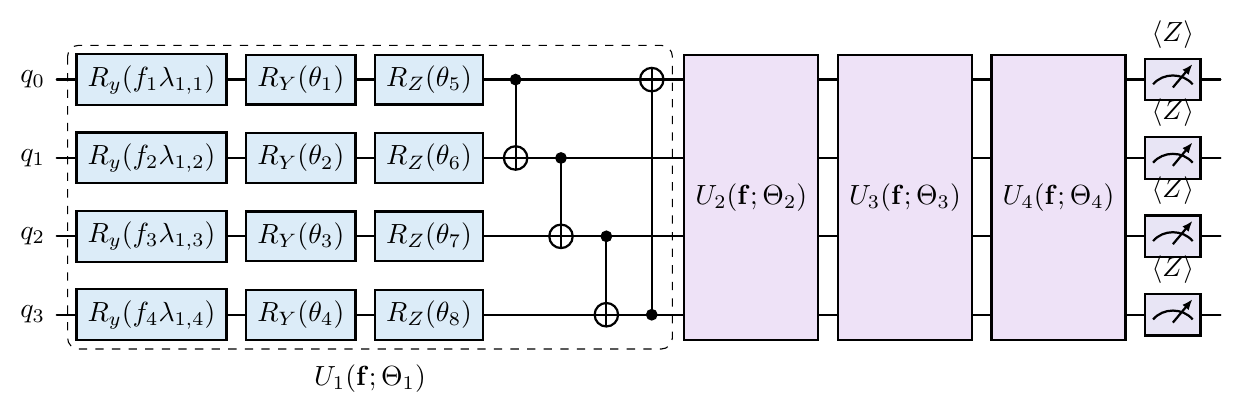


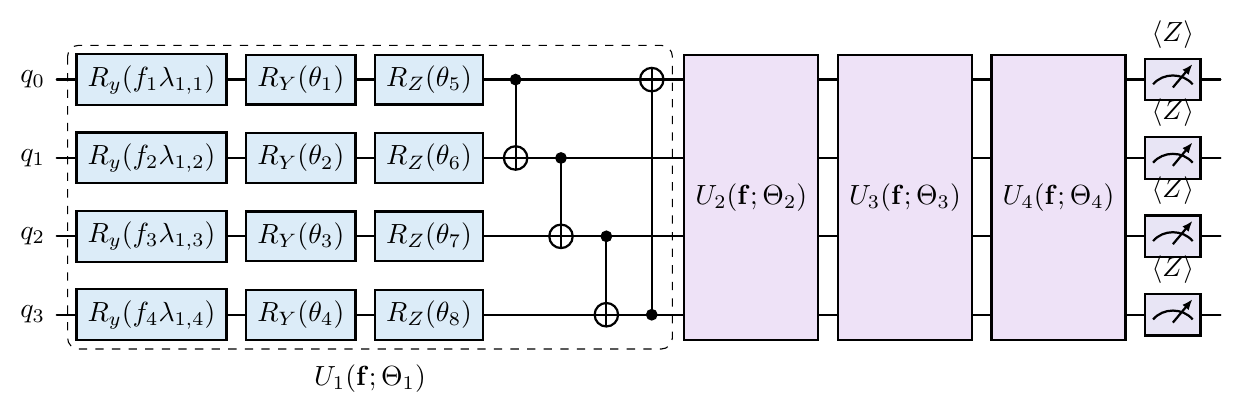


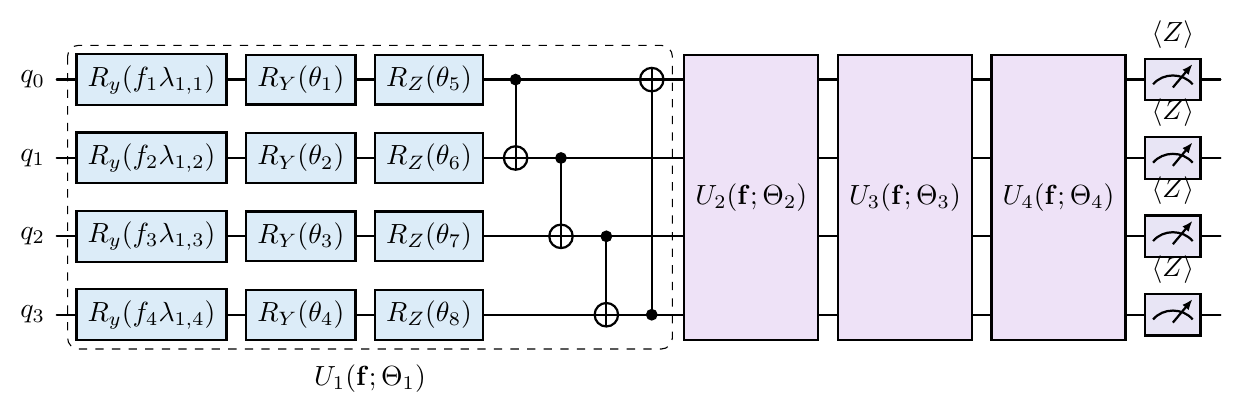


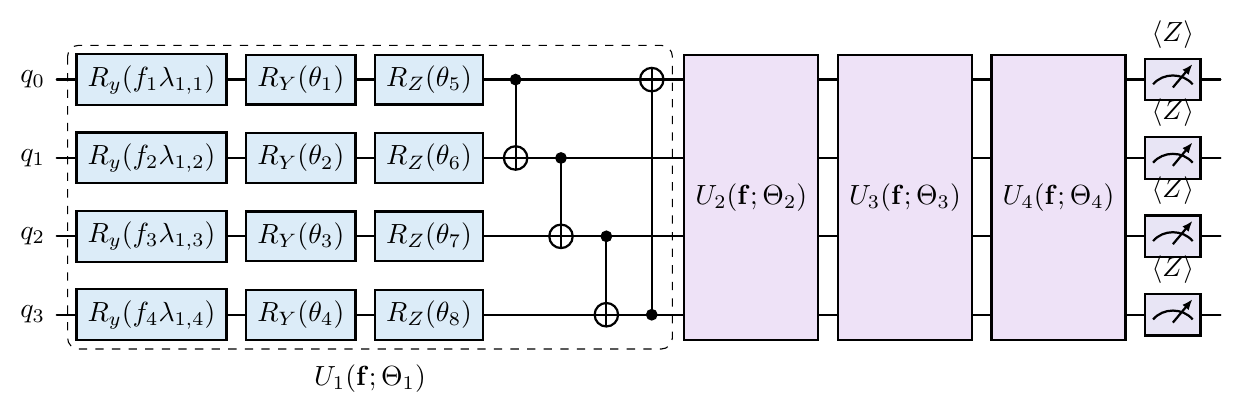


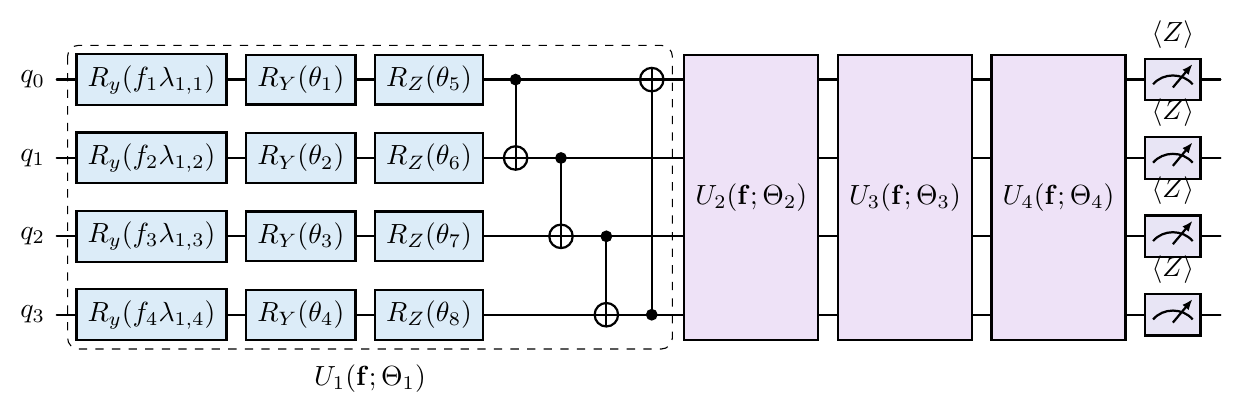

## Per Action

{
  "observables": [
    [
      "I 0",
      "Z 0",
      "Z 2"
    ],
    [
      "I 0",
      "Z 1",
      "Z 3"
    ]
  ],
  "fc_bias": false
}

### Seed 7

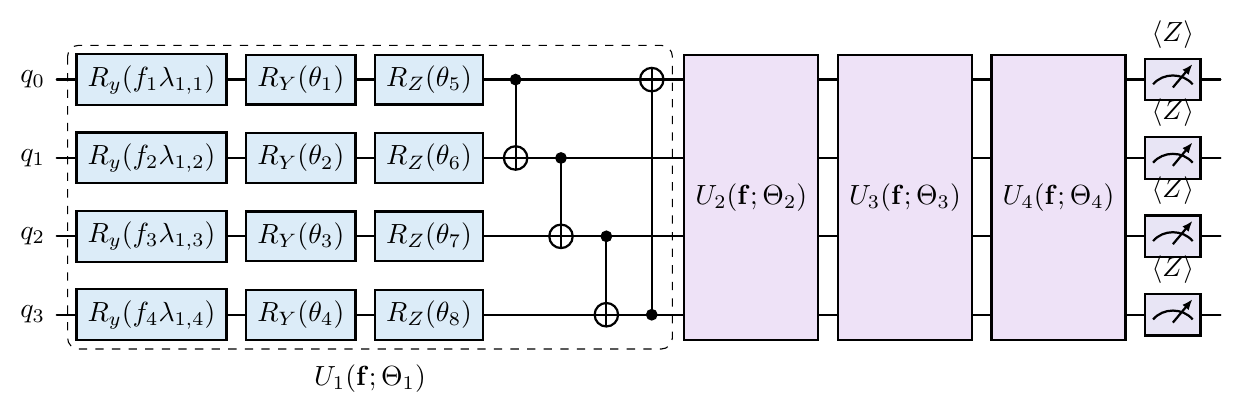


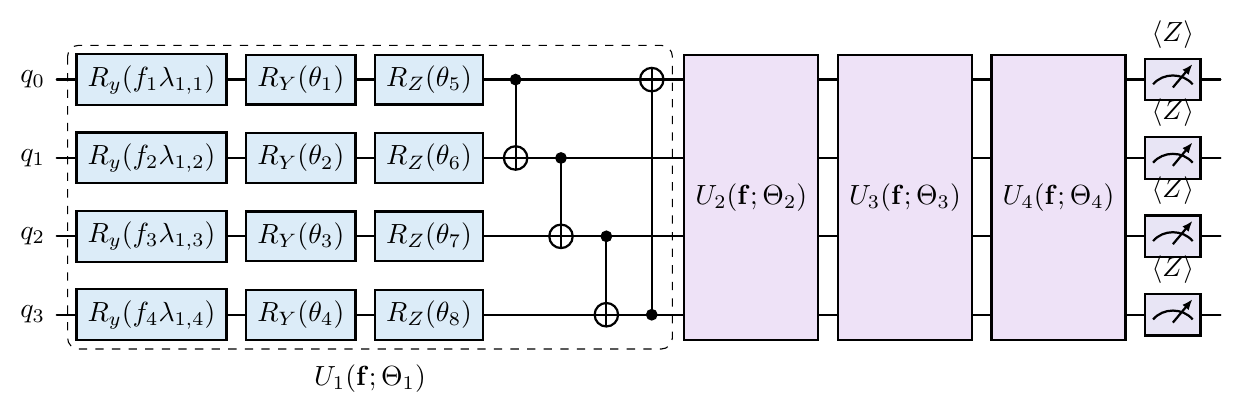


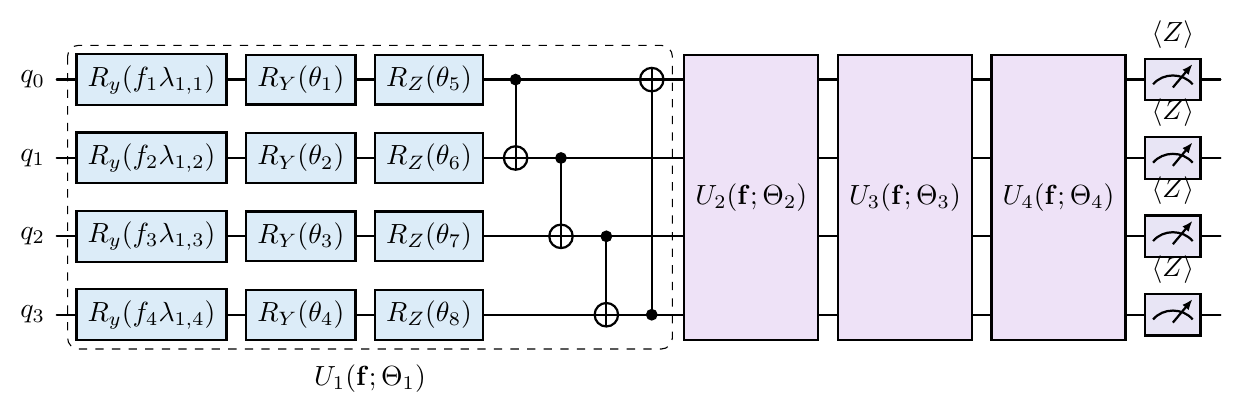


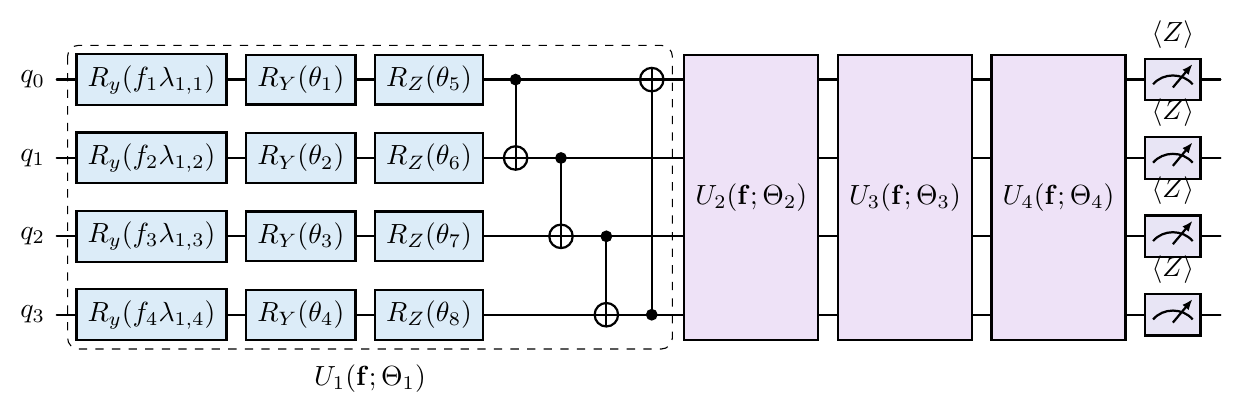


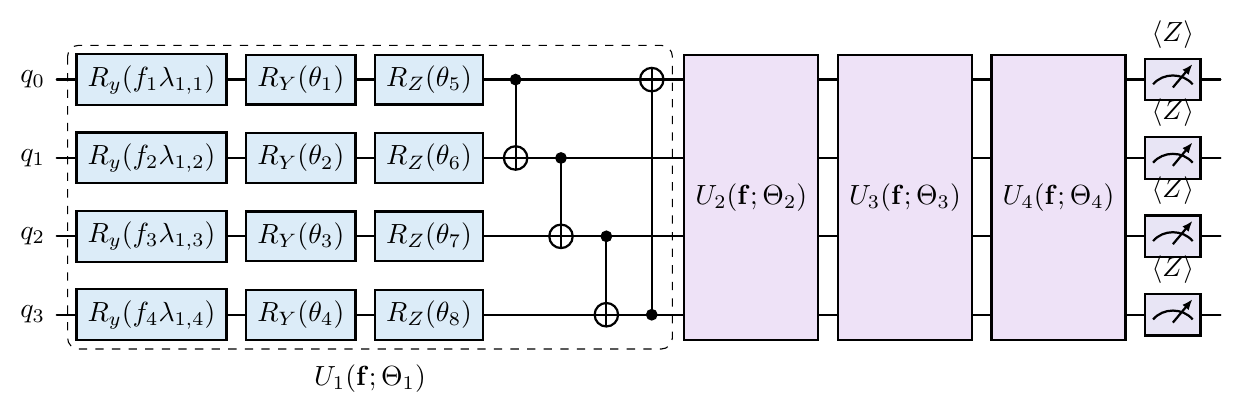

## Parity A2

{
  "observables": "parity-like",
  "preset_actions": 2,
  "fc_bias": true
}

### Seed 7

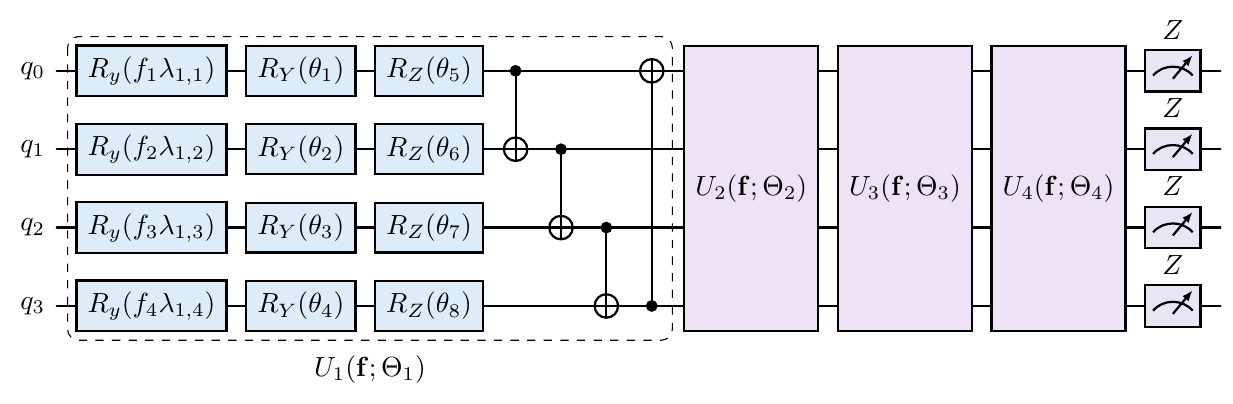


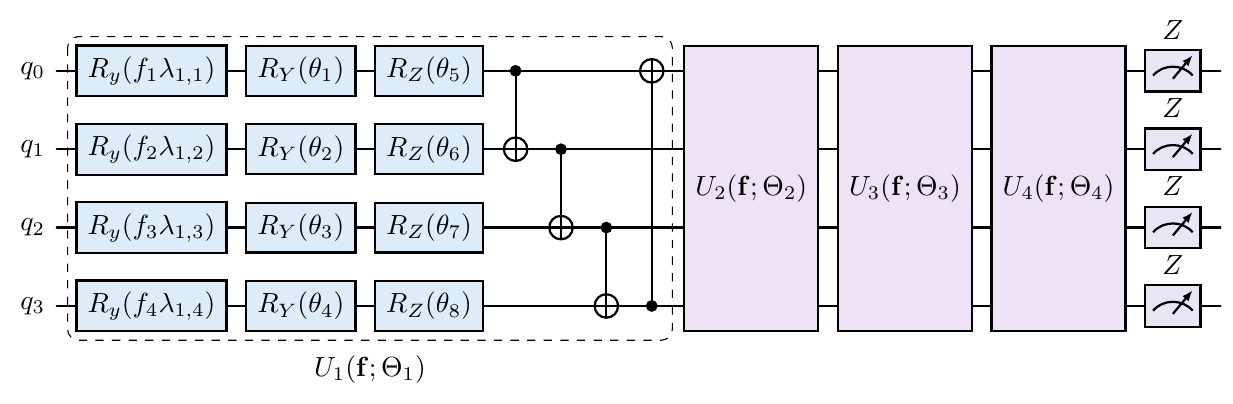


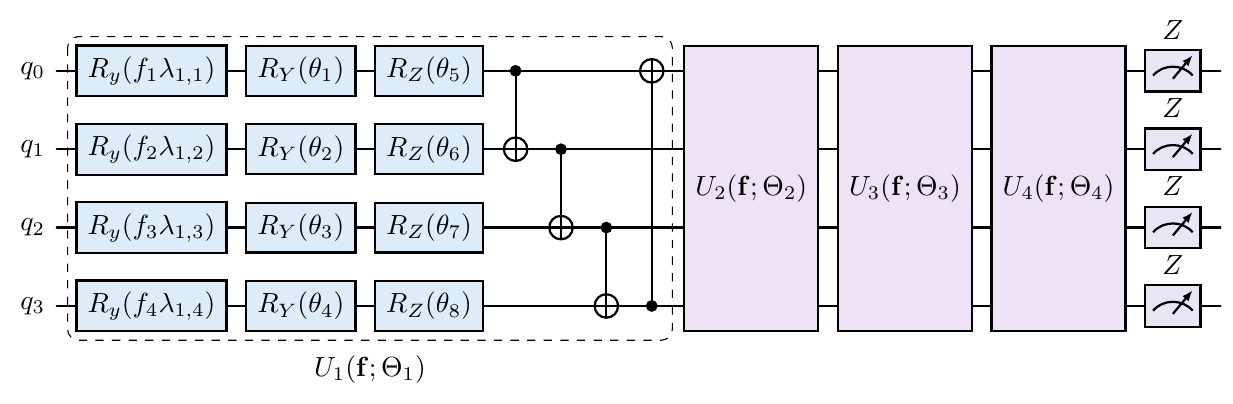


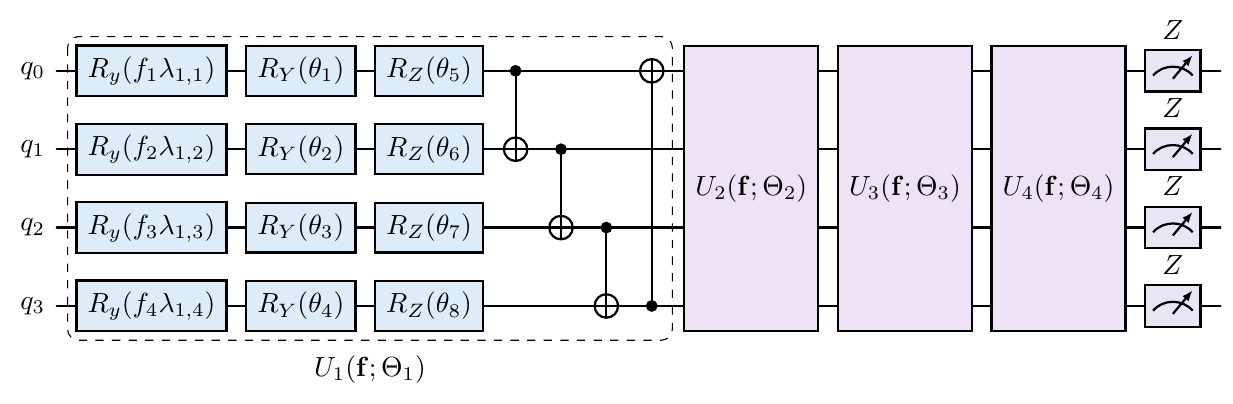


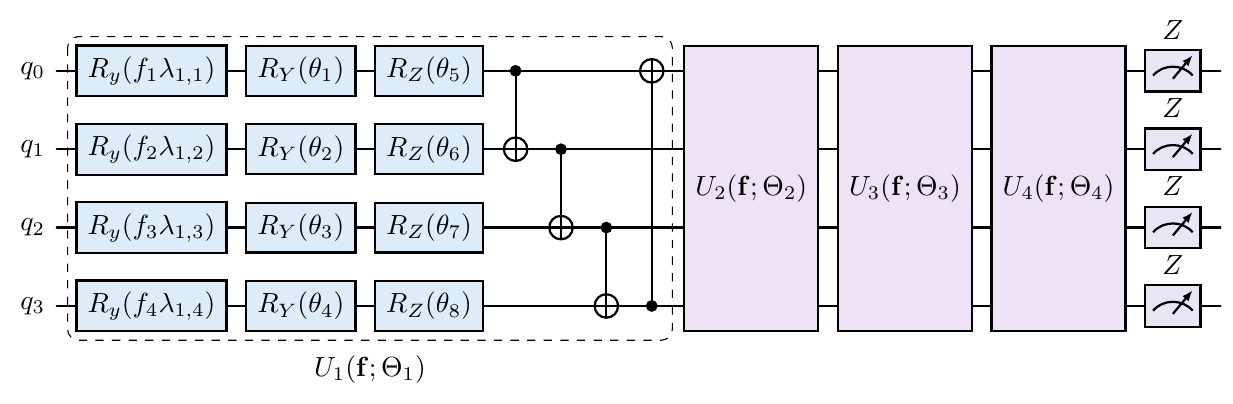

## Parity A4

{
  "observables": "parity-like",
  "preset_actions": 4,
  "fc_bias": true
}

### Seed 7

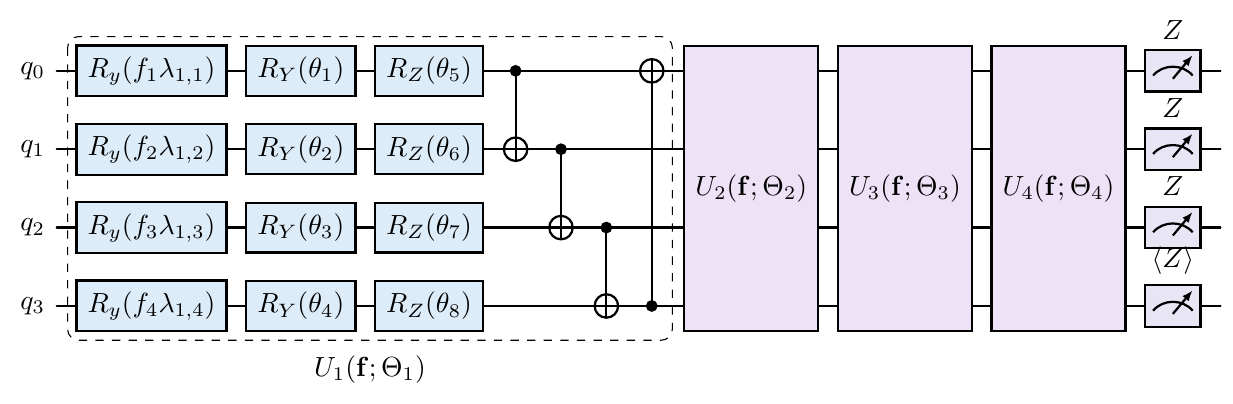


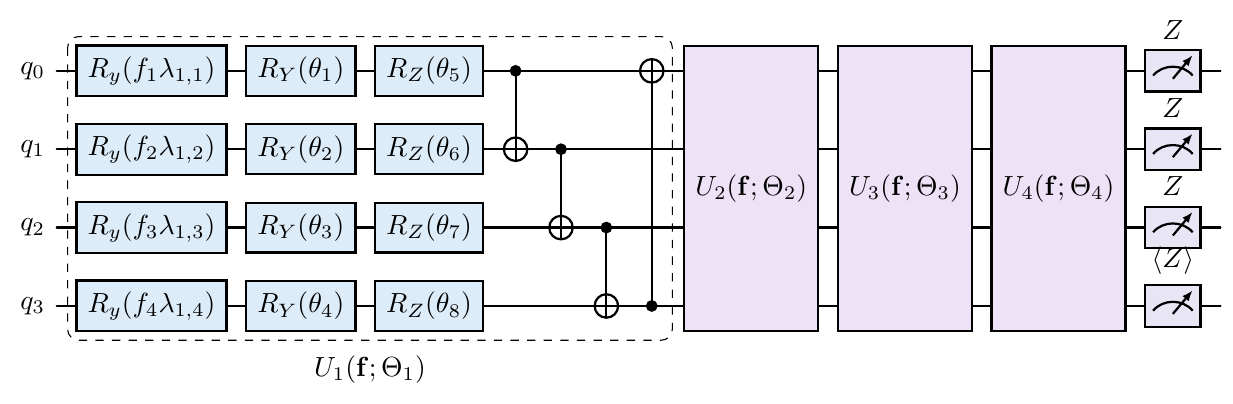


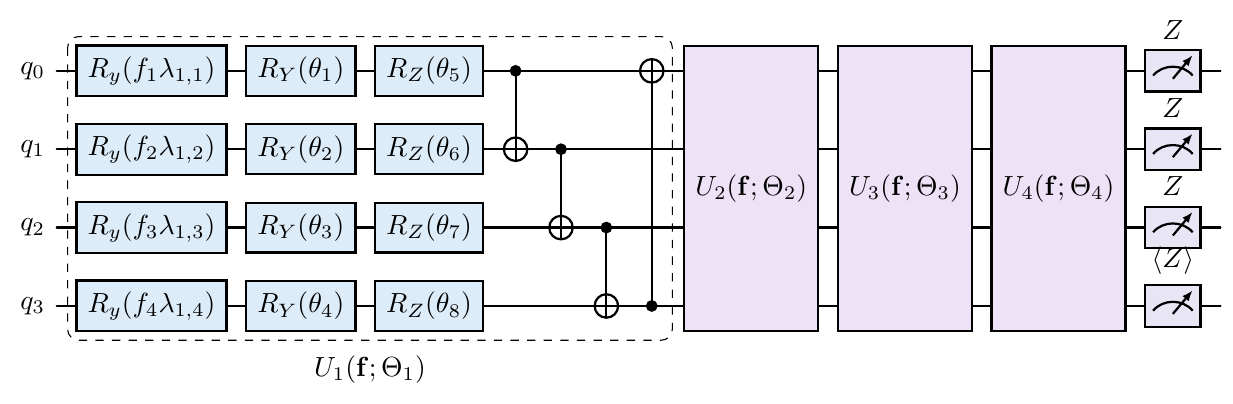


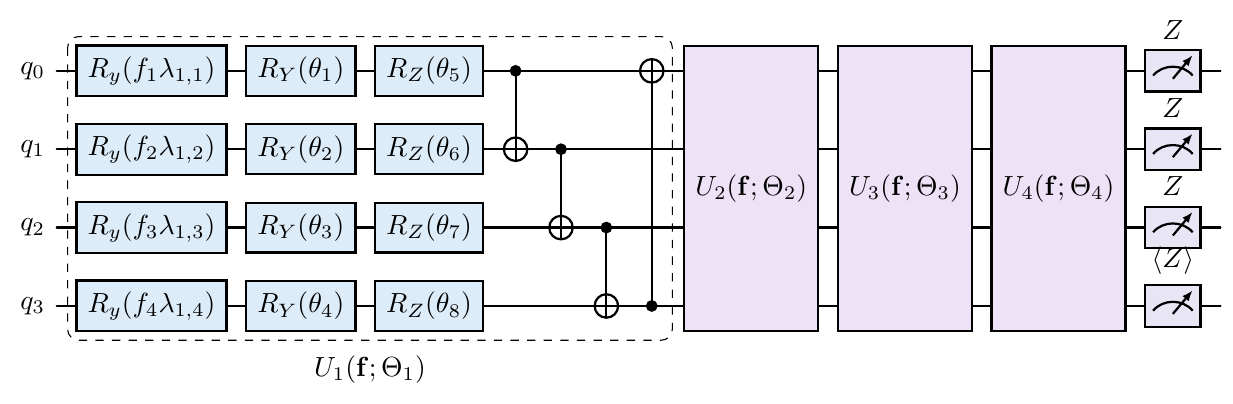


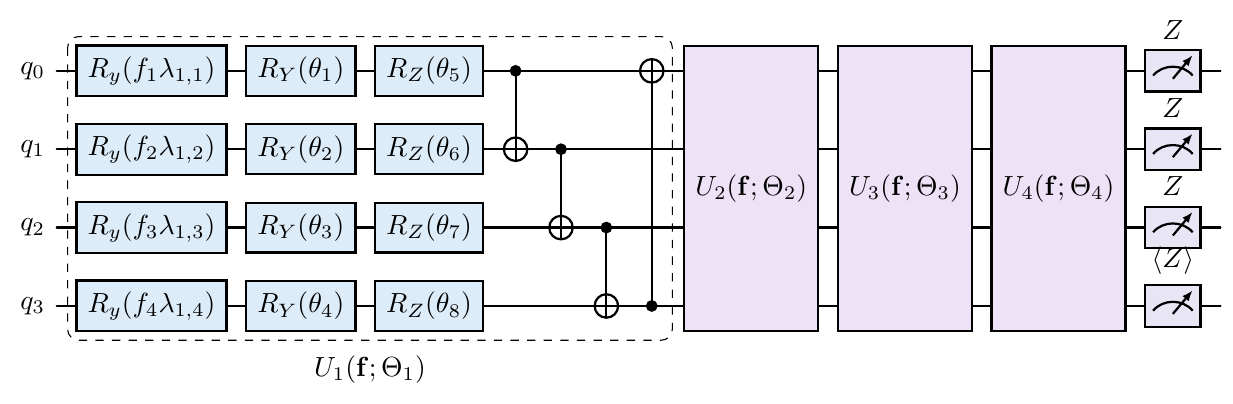

## Majority A2

{
  "observables": "majority-modulo",
  "preset_actions": 2,
  "majority_blocks": [
    [
      0,
      1,
      2,
      3
    ]
  ],
  "fc_bias": true
}

### Seed 7

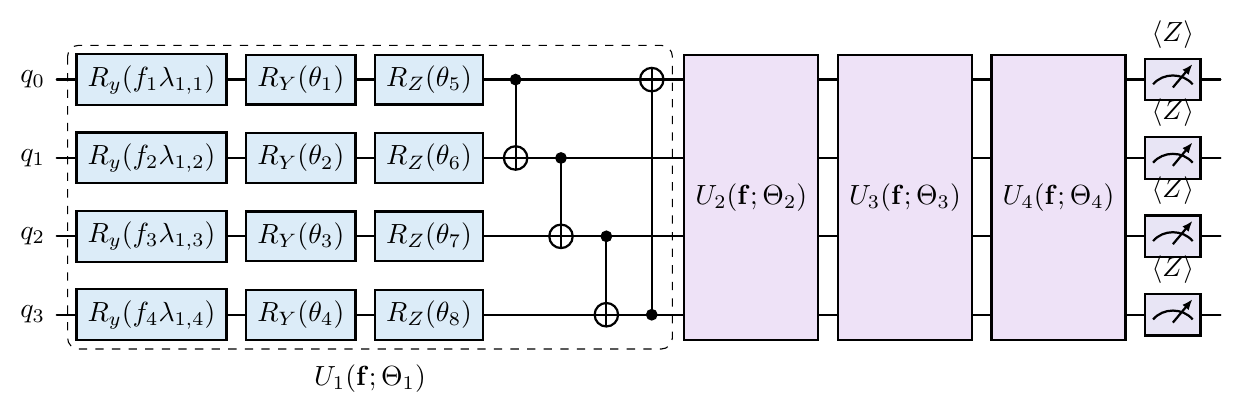


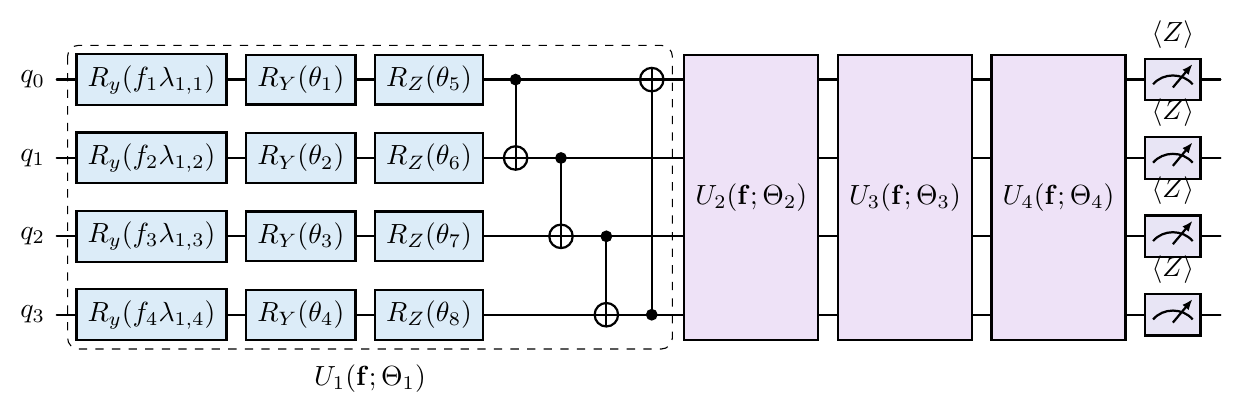


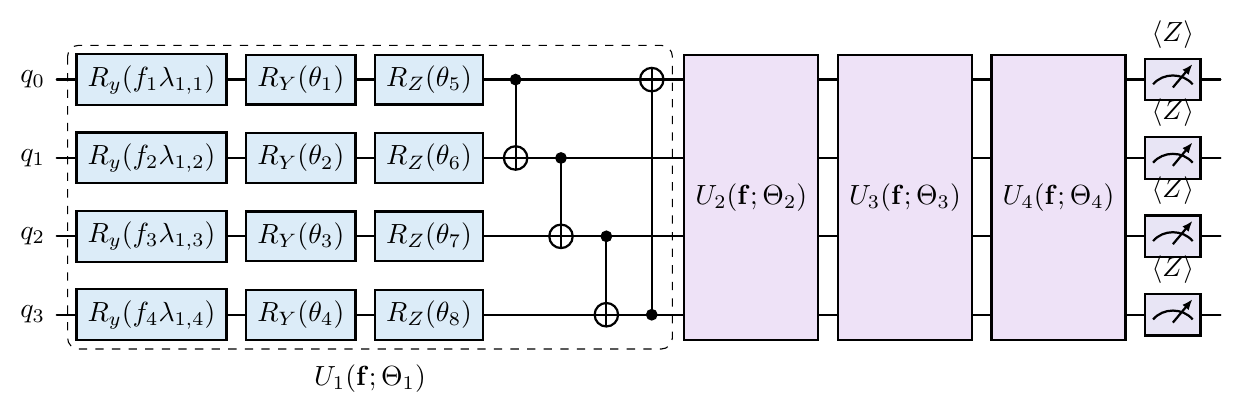


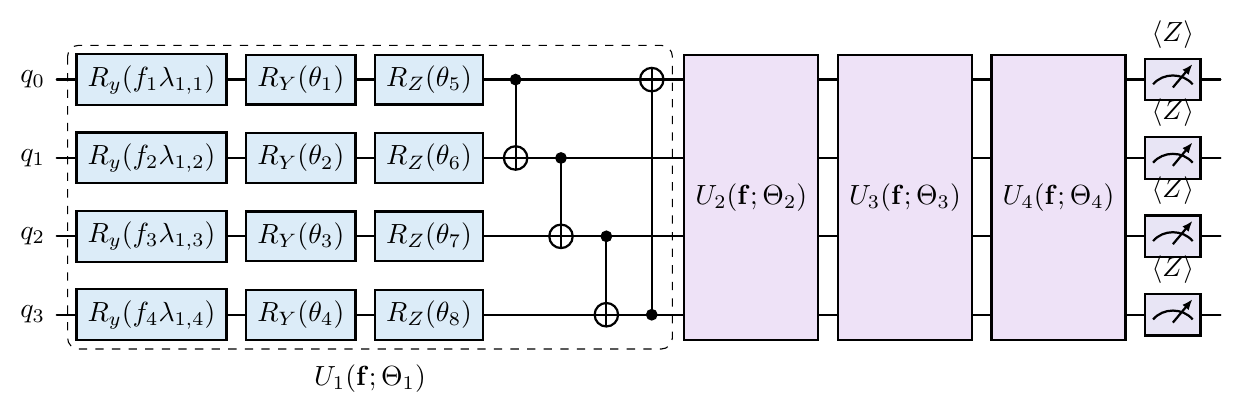


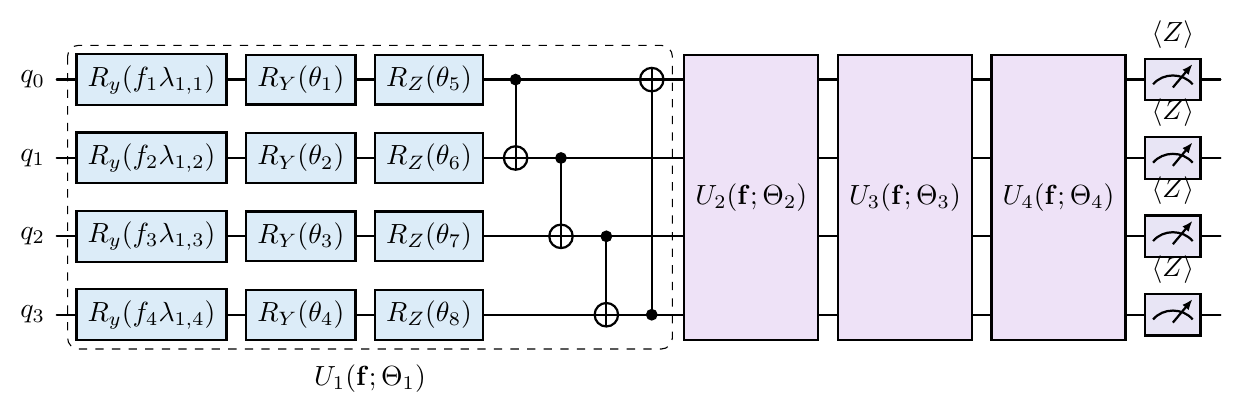

## Majority A4

{
  "observables": "majority-modulo",
  "preset_actions": 4,
  "majority_blocks": [
    [
      0,
      1,
      2
    ],
    [
      3
    ]
  ],
  "fc_bias": true
}

### Seed 7

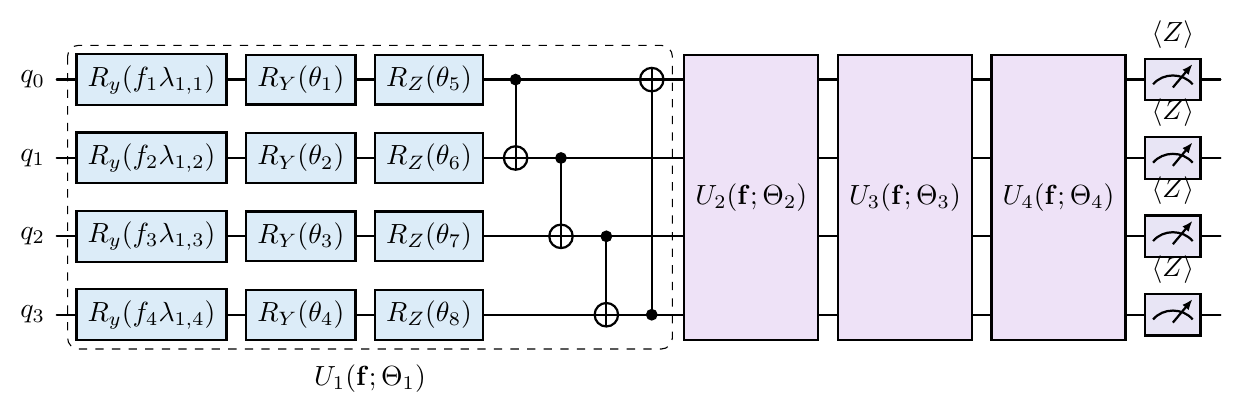


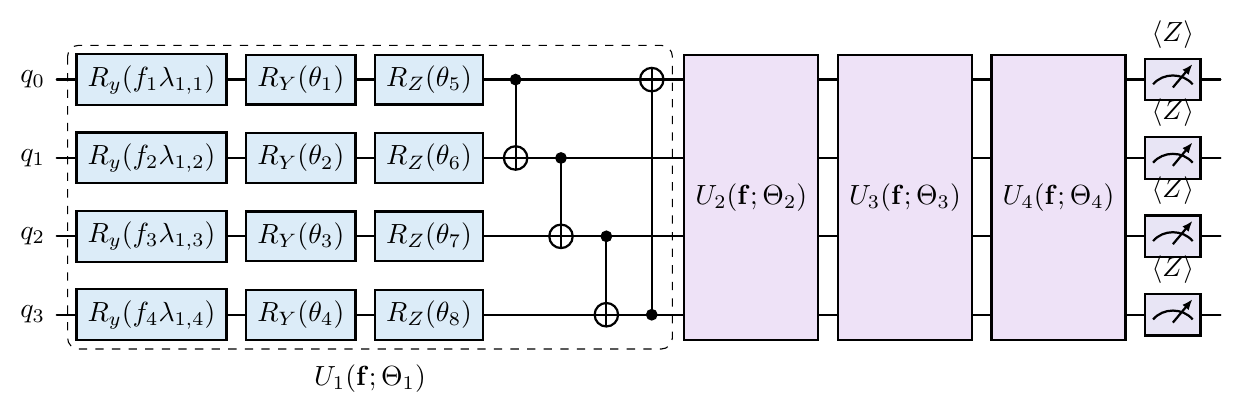


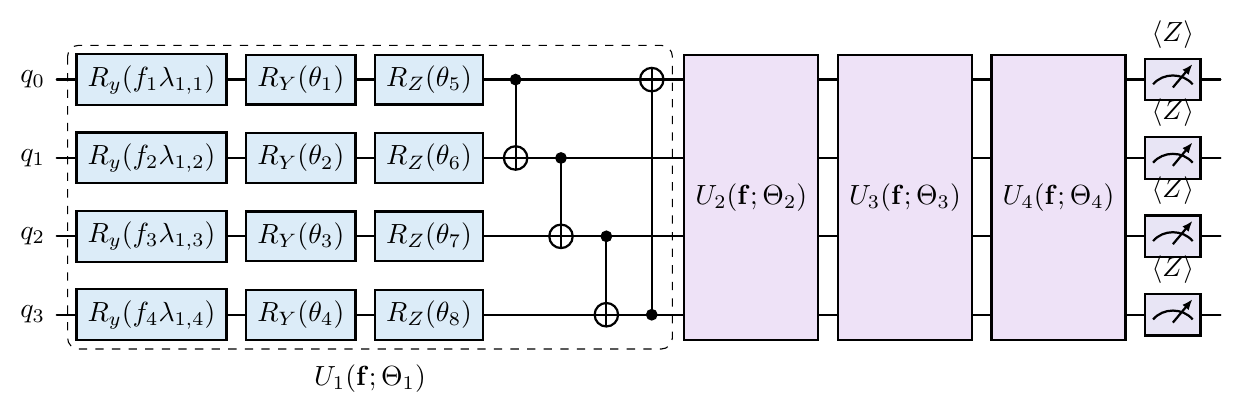


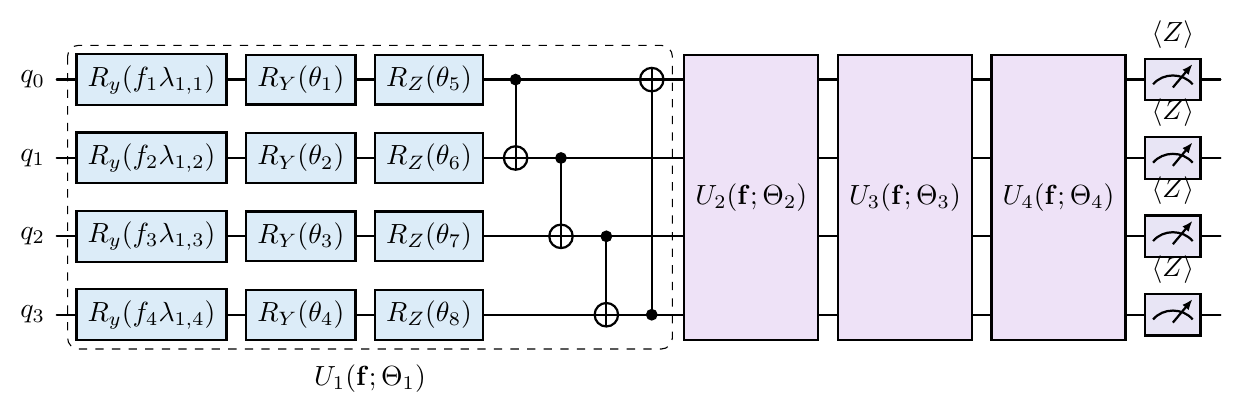


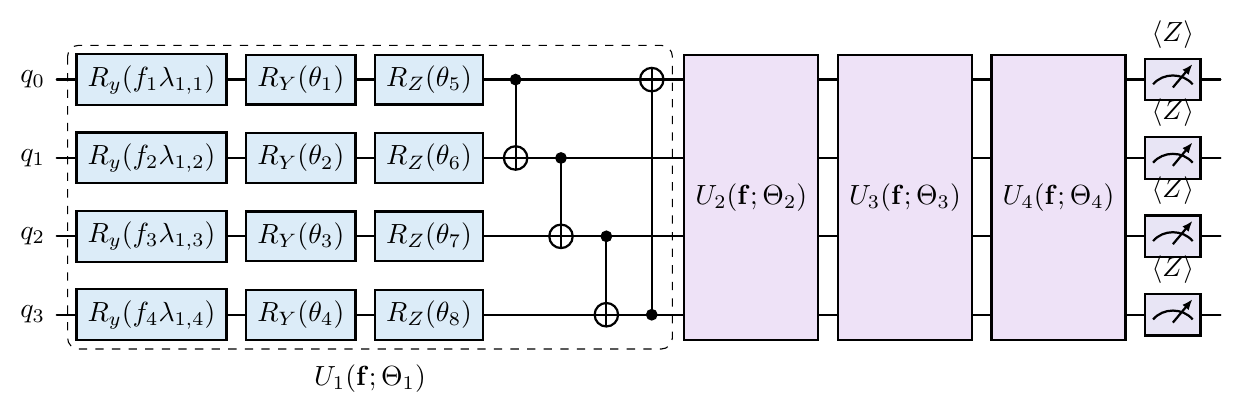

In [3]:
import base64
import html
from urllib.parse import quote

def drawing_links(paths):
    links = []
    for key, label in [("pdf", "Vector PDF"), ("tikz", "TikZ source"),
                       ("full_pdf", "Expanded vector PDF"), ("full_tikz", "Expanded source")]:
        relative = Path(paths[key]).relative_to(ROOT / "examples").as_posix()
        links.append(f'<a href="{quote(relative)}">{label}</a>')
    return " | ".join(links)

def show_drawing(paths, title):
    """Display a rendering of the vector Quantikz PDF, with paper sources."""
    display(Markdown("### " + title))
    display(Image(filename=paths["preview"], width=1200))
    source = Path(paths["tikz"]).read_text()
    display(HTML(drawing_links(paths) +
                 "<details><summary>Quantikz / TikZ source</summary><pre>" +
                 html.escape(source) + "</pre></details>"))

for name, readout in READOUTS.items():
    display(Markdown("## " + name.replace("_", " ").title()))
    display(Code(json.dumps(readout, indent=2), language="json"))
    for index, seed in enumerate(SEEDS):
        run_dir = OUTPUT / name / f"seed_{seed}"
        torch.manual_seed(seed)
        drawing_model = create_qfunction(dict(BASE_CONFIG, **readout), n_qubits=4, n_actions=2)
        paths = save_circuit_drawing(drawing_model, run_dir)
        del drawing_model
        if index == 0:
            show_drawing(paths, f"Seed {seed}")
        else:
            image_data = base64.b64encode(Path(paths["preview"]).read_bytes()).decode("ascii")
            source = html.escape(Path(paths["tikz"]).read_text())
            display(HTML(f'<details><summary>Seed {seed}: Quantikz circuit</summary>'
                         f'<img style="max-width:100%" src="data:image/png;base64,{image_data}">'
                         + drawing_links(paths) +
                         f'<details><summary>TikZ source</summary><pre>{source}</pre></details></details>'))


## Run the 30 independent training experiments

Each training model uses the specified readout and seed. Drawings are exported
from that initialized model through `draw_qfunction(output="tikz")`, using the
same shared exporter and `FULL_TIKZ` / `COMPRESSED_TIKZ` options as QASP's drawing
notebook. Both the compact and expanded PDFs are vector figures. The inline
previews are rendered from the PDFs. Saved `model.pt` files hold trained weights.

Each seed's complete training and evaluation returns are saved. Completion
markers are written after training, evaluation, and checkpoint verification.

In [ ]:
completed_runs = run_experiments(
    OUTPUT, base_config=BASE_CONFIG, readouts=READOUTS, training=TRAINING,
    seeds=SEEDS, episodes=EPISODES, max_workers=MAX_WORKERS,
    eval_episodes=EVAL_EPISODES, held_out_episodes=HELD_OUT_EPISODES,
)
assert len(completed_runs) == len(READOUTS) * len(SEEDS)
assert completed_runs.groupby("readout")["seed"].nunique().eq(5).all()
display(completed_runs[["readout", "seed", "episodes", "updates", "held_out_mean"]]
        .sort_values(["readout", "seed"]))

## Mean moving returns across training seeds

For each seed separately, compute a trailing **20-episode arithmetic mean**
with a full window. Then, at each episode, take the mean over the five seed
curves. Shading is **±1 sample standard deviation across those five moving
averages**, not a confidence interval and not variability across individual
episodes. Episodes 1–19 are omitted. Runs are never concatenated before
smoothing, so windows cannot cross seed boundaries.

The horizontal axis is episode number; equal episode budgets can yield
different environment-step counts when policies survive for different lengths.

In [ ]:
history, moving, run_summaries, summary = aggregate_results(OUTPUT, window=MOVING_WINDOW)
assert history.groupby(["readout", "seed"]).size().eq(EPISODES).all()
assert moving.loc[moving["episode"] >= MOVING_WINDOW, "count"].eq(5).all()
assert summary["runs"].eq(5).all()
display(summary.round(2))

fig, ax = plt.subplots(figsize=(11, 6))
labels = {"shared": "Shared Pauli features", "per_action": "Per-action sums",
          "parity_a2": "Parity a=2", "parity_a4": "Parity a=4",
          "majority_a2": "Majority a=2", "majority_a4": "Majority a=4"}
for name in READOUTS:
    curve = moving[(moving["readout"] == name) & (moving["episode"] >= MOVING_WINDOW)]
    x, mean, std = [curve[column].to_numpy() for column in ["episode", "mean", "std"]]
    line, = ax.plot(x, mean, label=labels[name], linewidth=2)
    ax.fill_between(x, mean - std, mean + std, color=line.get_color(), alpha=0.16)
ax.set(xlabel="Training episode", ylabel="20-episode moving return",
       title="CartPole-v1 · 4 layers · CNOT ring · 5 seeds per readout")
ax.legend(title="Mean ± 1 SD across seeds")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT / "average_moving_returns.png", dpi=160)
fig.savefig(OUTPUT / "average_moving_returns.pdf")
display(Image(filename=str(OUTPUT / "average_moving_returns.png")))
plt.close(fig)

## Held-out greedy evaluation and saved artifacts

Every final model is evaluated on the same 100 held-out reset seeds
(30000–30099). Summary statistics treat each trained model as one independent
replicate; they do not treat 500 evaluation episodes as 500 trained models.
These evaluation returns are separate from the exploratory training curves.

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
for index, name in enumerate(READOUTS):
    scores = run_summaries.loc[run_summaries["readout"] == name, "held_out_mean"].to_numpy()
    ax.scatter(index + np.linspace(-0.12, 0.12, len(scores)), scores, alpha=0.75)
    ax.errorbar(index, scores.mean(), yerr=scores.std(ddof=1), fmt="k_", capsize=6)
ax.set_xticks(range(len(READOUTS)), [labels[name] for name in READOUTS])
ax.set(ylabel="Mean held-out return per trained model", ylim=(0, 510))
ax.axhline(475, color="grey", linestyle="--", label="475 reference")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "held_out_returns.png", dpi=160)
fig.savefig(OUTPUT / "held_out_returns.pdf")
display(Image(filename=str(OUTPUT / "held_out_returns.png")))
plt.close(fig)
print("Saved:", OUTPUT)
print("30 checkpoints, per-run drawings and raw returns; aggregate CSVs, PNG and PDF plots.")

A high moving training return alone does not establish reliable convergence.
Inspect all five seed curves and held-out scores for each readout. Drawings show
the quantum circuit and measured observables; the fixed decomposition and
affine classical readout are described in the Q-function guide.

The source of the experiment runner is `examples/pqdqn_cartpole_experiment.py`.
Completed artifacts can be reloaded and replotted without retraining. Change
`OUTPUT` when changing circuit, readout, training budget, or software versions.